# 03 — Sentiment model: TF-IDF + Linear SVM (classical benchmark)

Amazon Fine Food Reviews — binary sentiment (positive vs negative; 3-star reviews excluded).

**Rules this notebook follows**
- One leakage-safe split (`GroupShuffleSplit`, groups = full review text). The split indices are saved so every other notebook uses the same test set.
- All tuning (GridSearchCV) uses the **training set only**. TF-IDF sits inside the Pipeline, so it is re-fitted on each CV training fold.
- The test set is used for reporting only. It never selects a model.
- SVM `decision_function` values are margins, **not probabilities**.

**How to run:** `Run All`. With `RUN_SEARCH = False` and a saved model it loads the tuned pipeline instead of searching (~30 min on CPU). The first run searches automatically.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support, roc_auc_score, classification_report)
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

SEED = 42
RUN_SEARCH = False          # True = re-run both GridSearches; False = load the saved pipeline
NEG, POS = "negative", "positive"
EXPECTED = {"train": 291_276, "test": 72_846}     # sizes documented for the final split

def find_root():
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if (d / "data" / "processed").exists():
            return d
    raise FileNotFoundError("Run from inside the project (a folder containing data/processed).")

ROOT = find_root()
DATA_CSV = ROOT / "data" / "processed" / "reviews_cleaned.csv"
SPLIT_FILE = ROOT / "data" / "processed" / "split_indices.npz"
MODELS, RESULTS = ROOT / "models", ROOT / "reports" / "results"
MODELS.mkdir(parents=True, exist_ok=True); RESULTS.mkdir(parents=True, exist_ok=True)
MODEL_PATH, SEARCH_JSON = MODELS / "svm_pipeline.joblib", RESULTS / "svm_search_results.json"
if not (MODEL_PATH.exists() and SEARCH_JSON.exists()):
    RUN_SEARCH = True       # nothing saved yet, so the search must run

print("sklearn", sklearn.__version__, "| pandas", pd.__version__, "| root:", ROOT)

def metrics_row(name, y_true, y_pred):
    """One row of the model-comparison table (Negative is the minority class)."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[NEG, POS], zero_division=0)
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
            "Macro F1": f1_score(y_true, y_pred, average="macro"),
            "Neg Precision": p[0], "Neg Recall": r[0], "Neg F1": f[0],
            "Pos Precision": p[1], "Pos Recall": r[1], "Pos F1": f[1]}

sklearn 1.9.0 | pandas 3.0.5 | root: A:\DS-Review-AI


## 1. Data and leakage-safe split

Neutral (3-star) reviews are removed, leaving the binary dataset. Identical review texts are kept in the same split (`groups = full text`), so no exact text appears in both train and test. Note: this is `GroupShuffleSplit` with a class-balance check, not a stratified split.

In [2]:
df = pd.read_csv(DATA_CSV)
binary_df = df[df["sentiment_label"] != "neutral"].copy()
X = binary_df["full_text"].fillna("").astype(str)
y = binary_df["sentiment_label"]
print(f"Clean reviews: {len(df):,} | binary reviews: {len(binary_df):,}")
print((y.value_counts(normalize=True) * 100).round(2).to_string())

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(X, y, groups=X))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

assert len(X_train) == EXPECTED["train"], f"train size {len(X_train):,} != {EXPECTED['train']:,}"
assert len(X_test) == EXPECTED["test"], f"test size {len(X_test):,} != {EXPECTED['test']:,}"
overlap = len(set(X_train) & set(X_test))
assert overlap == 0, f"{overlap} identical texts appear in both splits"

print(f"\nTrain {len(X_train):,} | Test {len(X_test):,} | exact text overlap: {overlap}")
print("Positive share  train: %.2f%%  test: %.2f%%" % ((y_train == POS).mean() * 100, (y_test == POS).mean() * 100))
np.savez(SPLIT_FILE, train_index=X_train.index.values, test_index=X_test.index.values)
print("Saved split indices ->", SPLIT_FILE.relative_to(ROOT))

Clean reviews: 393,890 | binary reviews: 364,122
sentiment_label
positive    84.32
negative    15.68

Train 291,276 | Test 72,846 | exact text overlap: 0
Positive share  train: 84.30%  test: 84.39%
Saved split indices -> data\processed\split_indices.npz


## 2. Hyperparameter tuning (training data only)

Two documented stages:

1. **TF-IDF settings** — `max_features` x `ngram_range` x `C` (min_df = 5), 2-fold CV, scoring Macro-F1.
2. **Class weighting** — `class_weight` (None / balanced) x `C` on the stage-1 TF-IDF settings, 4-fold CV, scoring Macro-F1.

Why Macro-F1: the data is ~84% positive / 16% negative, so accuracy alone would hide poor performance on the negative class.
`class_weight="balanced"` makes errors on the minority class cost more (weight = n_samples / (2 x class_count)); it was tested rather than assumed to help.

Stage 2 also switches on `sublinear_tf=True`. That was not isolated as its own factor, and stage 2 uses 4 folds while stage 1 used 2, so their CV scores are not directly comparable.

In [3]:
def svm_pipeline(tfidf_params):
    return Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                     ("clf", LinearSVC(max_iter=2000, random_state=SEED))])

if RUN_SEARCH:
    t0 = time.time()
    s1 = GridSearchCV(
        svm_pipeline({"min_df": 5}),
        {"tfidf__max_features": [20_000, 40_000], "tfidf__ngram_range": [(1, 2), (1, 3)], "clf__C": [0.5, 1.0]},
        cv=StratifiedKFold(2, shuffle=True, random_state=SEED), scoring="f1_macro", n_jobs=2)
    s1.fit(X_train, y_train)
    best1 = s1.best_params_

    tfidf_params = {"max_features": best1["tfidf__max_features"], "ngram_range": best1["tfidf__ngram_range"],
                    "min_df": 5, "sublinear_tf": True}
    s2 = GridSearchCV(
        svm_pipeline(tfidf_params),
        {"clf__class_weight": [None, "balanced"], "clf__C": [0.25, 0.5, 1.0, 2.0]},
        cv=StratifiedKFold(4, shuffle=True, random_state=SEED),
        scoring=["f1_macro", "accuracy"], refit="f1_macro", n_jobs=4)
    s2.fit(X_train, y_train)
    svm = s2.best_estimator_                       # already refit on the full training set
    cv_table = (pd.DataFrame(s2.cv_results_)[["param_clf__class_weight", "param_clf__C", "mean_test_f1_macro",
                                              "std_test_f1_macro", "mean_test_accuracy"]]
                .assign(param_clf__class_weight=lambda d: d["param_clf__class_weight"].map(lambda v: v if isinstance(v, str) else "None"))
                .sort_values("mean_test_f1_macro", ascending=False).reset_index(drop=True))
    cv_table.columns = ["class_weight", "C", "cv_macro_f1", "cv_macro_f1_std", "cv_accuracy"]
    search_record = {"stage1": {"cv": "StratifiedKFold(2)", "best_params": best1, "best_cv_macro_f1": s1.best_score_},
                     "stage2": {"cv": "StratifiedKFold(4)", "best_params": s2.best_params_,
                                "best_cv_macro_f1": s2.best_score_, "tfidf_params": tfidf_params,
                                "table": cv_table.to_dict("records")},
                     "minutes": round((time.time() - t0) / 60, 1)}
    SEARCH_JSON.write_text(json.dumps(search_record, indent=2, default=str))
    joblib.dump(svm, MODEL_PATH)
    print(f"Search finished in {search_record['minutes']} min; saved {MODEL_PATH.relative_to(ROOT)}")
else:
    svm = joblib.load(MODEL_PATH)
    search_record = json.loads(SEARCH_JSON.read_text())
    cv_table = pd.DataFrame(search_record["stage2"]["table"])
    print("Loaded saved pipeline and search results.")

print("Stage 1 best:", search_record["stage1"]["best_params"], "| CV Macro-F1 %.4f" % search_record["stage1"]["best_cv_macro_f1"])
print("Stage 2 best:", search_record["stage2"]["best_params"], "| CV Macro-F1 %.4f" % search_record["stage2"]["best_cv_macro_f1"])
print(cv_table.round(4).to_string())

Loaded saved pipeline and search results.
Stage 1 best: {'clf__C': 0.5, 'tfidf__max_features': 40000, 'tfidf__ngram_range': [1, 3]} | CV Macro-F1 0.9183
Stage 2 best: {'clf__C': 0.5, 'clf__class_weight': None} | CV Macro-F1 0.9219
  class_weight     C  cv_macro_f1  cv_macro_f1_std  cv_accuracy
0         None  0.50       0.9219           0.0007       0.9598
1         None  0.25       0.9217           0.0011       0.9601
2         None  1.00       0.9199           0.0005       0.9586
3         None  2.00       0.9153           0.0005       0.9559
4     balanced  0.50       0.9135           0.0003       0.9515
5     balanced  0.25       0.9123           0.0005       0.9503
6     balanced  1.00       0.9122           0.0008       0.9512
7     balanced  2.00       0.9093           0.0005       0.9500


## 3. Final held-out test evaluation (reporting only)

The selected pipeline (chosen from training-set CV) is scored once on the 72,846 test reviews.

              precision    recall  f1-score   support

    negative     0.9040    0.8444    0.8732     11372
    positive     0.9716    0.9834    0.9775     61474

    accuracy                         0.9617     72846
   macro avg     0.9378    0.9139    0.9253     72846
weighted avg     0.9610    0.9617    0.9612     72846

ROC-AUC: 0.9854
TN=9,603  FP=1,769 | FN=1,020  TP=60,454

Reproducibility check (this run vs documented):
  accuracy  0.9617 vs 0.9617  (diff +0.0000)
  macro_f1  0.9253 vs 0.9253  (diff +0.0000)
  roc_auc   0.9854 vs 0.9854  (diff -0.0000)


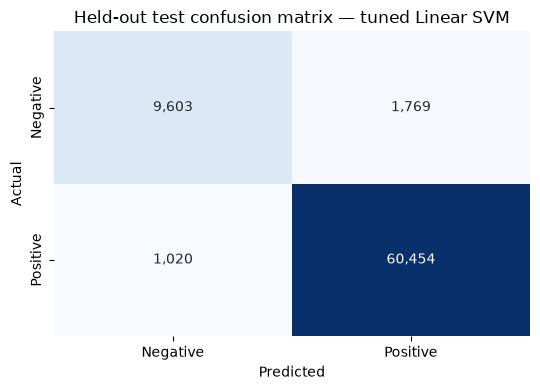

In [4]:
assert list(svm.classes_) == [NEG, POS]
y_pred = svm.predict(X_test)
scores = svm.decision_function(X_test)                  # margins, not probabilities
p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=[NEG, POS], zero_division=0)
cm = confusion_matrix(y_test, y_pred, labels=[NEG, POS]); tn, fp, fn, tp = (int(v) for v in cm.ravel())

svm_test = {"model": "TF-IDF + LinearSVC", "train_size": len(X_train), "test_size": len(X_test),
            "params": {k: str(v) for k, v in svm.get_params().items() if k in ("clf__C", "clf__class_weight",
                       "tfidf__max_features", "tfidf__ngram_range", "tfidf__min_df", "tfidf__sublinear_tf")},
            "accuracy": accuracy_score(y_test, y_pred), "macro_f1": f1_score(y_test, y_pred, average="macro"),
            "roc_auc": roc_auc_score((y_test == POS).astype(int), scores),
            "neg_precision": p[0], "neg_recall": r[0], "neg_f1": f[0],
            "pos_precision": p[1], "pos_recall": r[1], "pos_f1": f[1], "TN": tn, "FP": fp, "FN": fn, "TP": tp}
(RESULTS / "svm_test_results.json").write_text(json.dumps(
    {k: (round(v, 4) if isinstance(v, float) else v) for k, v in svm_test.items()}, indent=2))

print(classification_report(y_test, y_pred, labels=[NEG, POS], digits=4))
print("ROC-AUC: %.4f" % svm_test["roc_auc"])
print(f"TN={tn:,}  FP={fp:,} | FN={fn:,}  TP={tp:,}")

DOCUMENTED = {"accuracy": 0.9617, "macro_f1": 0.9253, "roc_auc": 0.9854}   # figures recorded in the project log
print("\nReproducibility check (this run vs documented):")
for k, v in DOCUMENTED.items():
    print(f"  {k:9s} {svm_test[k]:.4f} vs {v:.4f}  (diff {svm_test[k] - v:+.4f})")

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
ax.set(xlabel="Predicted", ylabel="Actual", title="Held-out test confusion matrix — tuned Linear SVM")
plt.tight_layout(); plt.show()

## 4. Baseline model comparison

All baselines use the same TF-IDF configuration as the tuned SVM, fitted on the training set only. The test set is used here to **report** results, not to choose a model.

In [5]:
tfidf = clone(svm.named_steps["tfidf"])
Xtr, Xte = tfidf.fit_transform(X_train), tfidf.transform(X_test)

baselines = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression (default)": LogisticRegression(max_iter=1000, random_state=SEED),
    "Logistic Regression (balanced)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED),
    "Linear SVM (C=1, default)": LinearSVC(max_iter=2000, random_state=SEED),
    "Linear SVM (C=1, balanced)": LinearSVC(class_weight="balanced", max_iter=2000, random_state=SEED),
}
rows = [metrics_row(name, y_test, clf.fit(Xtr, y_train).predict(Xte)) for name, clf in baselines.items()]
rows.append(metrics_row("Linear SVM (tuned: C=0.5, class_weight=None)", y_test, y_pred))
comparison = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).round(4)
comparison.to_csv(ROOT / "reports" / "model_comparison.csv", index=False)
print(comparison.to_string(index=False))

                                       Model  Accuracy  Macro F1  Neg Precision  Neg Recall  Neg F1  Pos Precision  Pos Recall  Pos F1
Linear SVM (tuned: C=0.5, class_weight=None)    0.9617    0.9253         0.9040      0.8444  0.8732         0.9716      0.9834  0.9775
                   Linear SVM (C=1, default)    0.9600    0.9223         0.8927      0.8451  0.8682         0.9716      0.9812  0.9764
               Logistic Regression (default)    0.9575    0.9149         0.9162      0.8010  0.8547         0.9640      0.9864  0.9751
                  Linear SVM (C=1, balanced)    0.9518    0.9131         0.8052      0.9114  0.8551         0.9832      0.9592  0.9711
              Logistic Regression (balanced)    0.9467    0.9069         0.7697      0.9394  0.8461         0.9883      0.9480  0.9677
                                 Naive Bayes    0.9371    0.8692         0.8771      0.6942  0.7750         0.9455      0.9820  0.9634
                           Majority baseline    0.8439 

## 5. Error analysis

False positives = negative reviews predicted positive; false negatives = positive reviews predicted negative.

In [6]:
errors = pd.DataFrame({"text": X_test.values, "true": y_test.values, "pred": y_pred, "score": scores})
errors["correct"] = errors["true"] == errors["pred"]
errors["length"] = errors["text"].str.len()
errors["has_html"] = errors["text"].str.contains(r"<br|<a href", regex=True)
fps = errors[(errors["true"] == NEG) & (errors["pred"] == POS)]
fns = errors[(errors["true"] == POS) & (errors["pred"] == NEG)]
print(f"False positives: {len(fps):,} ({len(fps)/len(errors):.2%}) | False negatives: {len(fns):,} ({len(fns)/len(errors):.2%})")

for title, part in [("FALSE POSITIVES (true negative, predicted positive)", fps),
                    ("FALSE NEGATIVES (true positive, predicted negative)", fns)]:
    print(f"\n--- {title}: 8 random examples ---")
    for _, row in part.sample(min(8, len(part)), random_state=SEED).iterrows():
        print(f"[{row['length']} chars | margin {row['score']:+.2f}] {row['text'][:160]}")

print("\nText length, correct vs misclassified:")
print(errors.groupby("correct")["length"].agg(["count", "mean", "median"]).round(1).to_string())
print("\nShare of reviews containing raw HTML tags (<br>, <a href>): all %.1f%% | misclassified %.1f%%"
      % (errors["has_html"].mean() * 100, errors.loc[~errors["correct"], "has_html"].mean() * 100))
near = errors["score"].abs() < 0.5
print(f"Reviews within 0.5 of the decision boundary: {near.sum():,} ({near.mean():.1%}); "
      f"{(~errors.loc[near, 'correct']).sum():,} of them misclassified")

False positives: 1,769 (2.43%) | False negatives: 1,020 (1.40%)

--- FALSE POSITIVES (true negative, predicted positive): 8 random examples ---
[139 chars | margin +1.55] Love those Suzie's I love Suzie's flatbreads!  I had some from another store and they quit carrying them, so I ordered them through Amazon.
[1108 chars | margin +0.86] So close to perfect... I love(d) these bars. They taste like a candy bar, have fiber, fill me up, whats not to like!<br />Oh wait... they use SOY PROTEIN.<br />
[212 chars | margin +0.28] Great if you love to eat insects They use carmine (cochineal) to color this. In other words, crushed insects. I'd rather have it not such a vibrant color and in
[1043 chars | margin +0.16] No plum taste, just full of salt This is very cheaply created Umeboshi and no true taste. It has uncured runny meat, just full of salt. Obviously it was not sun
[155 chars | margin +1.56] Extra Virgin Coconut Oil The Garden of LIfe Extra Virgin Coconut Oil is very thick. When mixed w

## 6. Interpretation — Linear SVM coefficients

Positive coefficients push toward **Positive**, negative toward **Negative**. These are associations learned by this model, not causes, and they say nothing about how often a phrase occurs.

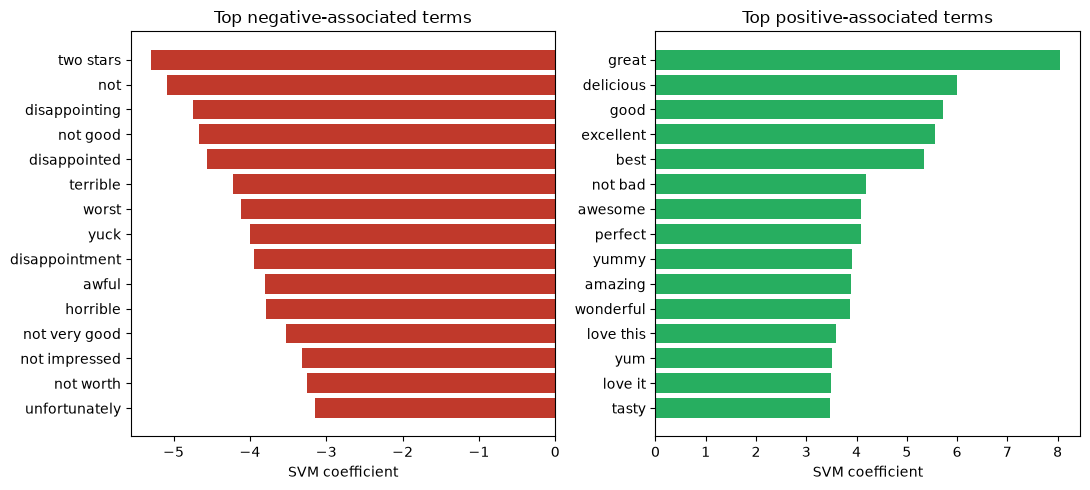

In [7]:
names = svm.named_steps["tfidf"].get_feature_names_out()
coef = svm.named_steps["clf"].coef_[0]            # classes_ = [negative, positive]
order = np.argsort(coef)
top_pos = pd.DataFrame({"term": names[order[::-1][:20]], "coefficient": coef[order[::-1][:20]]})
top_neg = pd.DataFrame({"term": names[order[:20]], "coefficient": coef[order[:20]]})
pd.concat([top_pos.assign(side="positive"), top_neg.assign(side="negative")]).to_csv(
    RESULTS / "svm_top_coefficients.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, tbl, colour, title in [(axes[0], top_neg.head(15), "#c0392b", "Top negative-associated terms"),
                               (axes[1], top_pos.head(15), "#27ae60", "Top positive-associated terms")]:
    ax.barh(tbl["term"][::-1], tbl["coefficient"][::-1], color=colour)
    ax.set(title=title, xlabel="SVM coefficient")
plt.tight_layout(); plt.show()

## 7. Final model record

In [8]:
s2 = search_record["stage2"]
print("Model            : TF-IDF + LinearSVC (saved to", MODEL_PATH.relative_to(ROOT), ")")
print("TF-IDF           :", s2["tfidf_params"])
print("Selected         :", s2["best_params"])
print("CV (train only)  : Macro-F1 %.4f, %s" % (s2["best_cv_macro_f1"], s2["cv"]))
print("Held-out test    : accuracy %.4f | Macro-F1 %.4f | ROC-AUC %.4f | negative recall %.4f"
      % (svm_test["accuracy"], svm_test["macro_f1"], svm_test["roc_auc"], svm_test["neg_recall"]))
print("Test errors      : %d false positives, %d false negatives" % (svm_test["FP"], svm_test["FN"]))

Model            : TF-IDF + LinearSVC (saved to models\svm_pipeline.joblib )
TF-IDF           : {'max_features': 40000, 'ngram_range': [1, 3], 'min_df': 5, 'sublinear_tf': True}
Selected         : {'clf__C': 0.5, 'clf__class_weight': None}
CV (train only)  : Macro-F1 0.9219, StratifiedKFold(4)
Held-out test    : accuracy 0.9617 | Macro-F1 0.9253 | ROC-AUC 0.9854 | negative recall 0.8444
Test errors      : 1769 false positives, 1020 false negatives


## Limitations

- Star rating is used as sentiment ground truth, so labels are noisy (for example mixed reviews and sarcasm).
- Classes are imbalanced (~84% / 16%); Macro-F1 and negative-class recall are reported alongside accuracy.
- Neutral (3-star) reviews are excluded, so the model cannot represent them.
- Review text contains raw HTML tags; the error analysis above shows how common they are. Cleaning them was not tried and could change results.
- Stage 1 and stage 2 of the search use different CV fold counts and `sublinear_tf`, so their CV scores should not be compared.
- Dataset is old (to 2012) and food-specific; this is a project model, not a production system.